# Redes Generativas Adversariales (GANs)

## ¿Qué son las GANs?

### La idea genial de Goodfellow (2014)

Ian Goodfellow propuso las GANs en 2014. La idea:

> Dos redes neuronales compiten entre sí como en un juego:
> una **genera** datos falsos y la otra intenta **detectar** si son reales o falsos.

```
                         GAN
    ┌─────────────────────────────────────────┐
    │                                         │
    │   Ruido z          Imagen generada      │
    │   ~ N(0,1)    ┌──────────┐              │
    │   ─────────▶  │GENERADOR │──▶ x_fake    │
    │               │  G(z)    │       │      │
    │               └──────────┘       │      │
    │                                  ▼      │
    │   Imagen real             ┌───────────┐ │
    │   del dataset ──────────▶ │DISCRIMINA-│ │
    │   x_real                  │DOR D(x)   │    ──▶ Real/Falso │
    │                           └───────────┘ │
    └─────────────────────────────────────────┘
```

### Analogía: El Falsificador y el Detective

- **Generador (G)** = Falsificador de billetes
  - Empieza generando billetes muy malos
  - Cada vez que el detective los detecta, mejora su técnica

- **Discriminador (D)** = Detective de billetes falsos
  - Examina billetes y dice si son reales o falsos
  - Se vuelve más experto detectando falsificaciones

**Con el tiempo**: los billetes falsos se vuelven **indistinguibles** de los reales.

### ¿Para qué sirven las GANs?

| Aplicación | Descripción |
|-----------|------------|
| **Generación de imágenes** | Rostros, arte, paisajes (StyleGAN, DALL-E precursor) |
| **Super-resolución** | Mejorar resolución de imágenes (SRGAN) |
| **Transferencia de estilo** | Convertir fotos en pinturas (CycleGAN) |
| **Síntesis de datos** | Generar datos de entrenamiento sintéticos |
| **Inpainting** | Rellenar partes faltantes de imágenes |
| **Traducción imagen→imagen** | Pix2Pix, día→noche, boceto→foto |
| **Deepfakes** | Generación de rostros/videos (uso controvertido) |

## Teoría Matemática

### El Juego Minimax

Las GANs se formulan como un **juego de suma cero** entre dos jugadores:

$$\boxed{\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]}$$

**Interpretación de cada término:**

| Término | Significado |
|---------|------------|
| $\log D(x)$ | D quiere **maximizar** esto → clasificar reales como reales ($D(x) \to 1$) |
| $\log(1 - D(G(z)))$ | D quiere **maximizar** → clasificar falsos como falsos ($D(G(z)) \to 0$) |
| G quiere **minimizar** | → que $D(G(z)) \to 1$ (engañar al discriminador) |

### Pérdida del Discriminador

El discriminador quiere clasificar correctamente:

$$\mathscr{L}_D = -\mathbb{E}_{x \sim p_{data}}[\log D(x)] - \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

Es una **binary cross-entropy**: real=1, falso=0.

### Pérdida del Generador

En la formulación original:
$$\mathscr{L}_G = \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

En la práctica se usa el **truco de no-saturación** (gradientes más fuertes al inicio):
$$\mathscr{L}_G = -\mathbb{E}_{z \sim p_z}[\log D(G(z))]$$

### Discriminador Óptimo

Para un generador fijo G, el discriminador óptimo es:

$$D^*(x) = \frac{p_{data}(x)}{p_{data}(x) + p_g(x)}$$

Cuando $p_g = p_{data}$ (generador perfecto): $D^*(x) = \frac{1}{2}$ para todo $x$.

### Convergencia y Divergencia

Cuando $D$ es óptimo, la función objetivo se convierte en:

$$V(D^*, G) = 2 \cdot D_{JS}(p_{data} \| p_g) - \log 4$$

Donde $D_{JS}$ es la **divergencia de Jensen-Shannon**.
El mínimo global se alcanza si y solo si $p_g = p_{data}$.

### Problemas del Entrenamiento de GANs

Las GANs son notoriamente **difíciles de entrenar**:

| Problema | Descripción | Solución |
|----------|------------|---------|
| **Mode collapse** | G genera solo unas pocas variantes | WGAN, mini-batch discrimination |
| **Vanishing gradients** | D es demasiado bueno → G no aprende | Non-saturating loss, label smoothing |
| **Inestabilidad** | El entrenamiento oscila sin converger | Spectral normalization, gradient penalty |
| **No convergencia** | No hay garantía de equilibrio de Nash | WGAN-GP, Progressive growing |

### Métricas de Evaluación

| Métrica | Qué mide | Mejor |
|---------|---------|-------|
| **IS** (Inception Score) | Calidad + diversidad | Mayor es mejor |
| **FID** (Fréchet Inception Distance) | Distancia entre distribuciones | Menor es mejor |
| **Visual inspection** | ¿Se ven reales? | Subjetivo |

## Ejemplo Numérico: GAN en 1D

Antes de implementar con redes neuronales, veamos cómo funciona
el juego GAN con una distribución simple en 1D.

EJEMPLO NUMÉRICO: GAN EN 1D

Distribución real: N(4.0, 1.5²)
El Generador debe aprender a generar datos de esta distribución


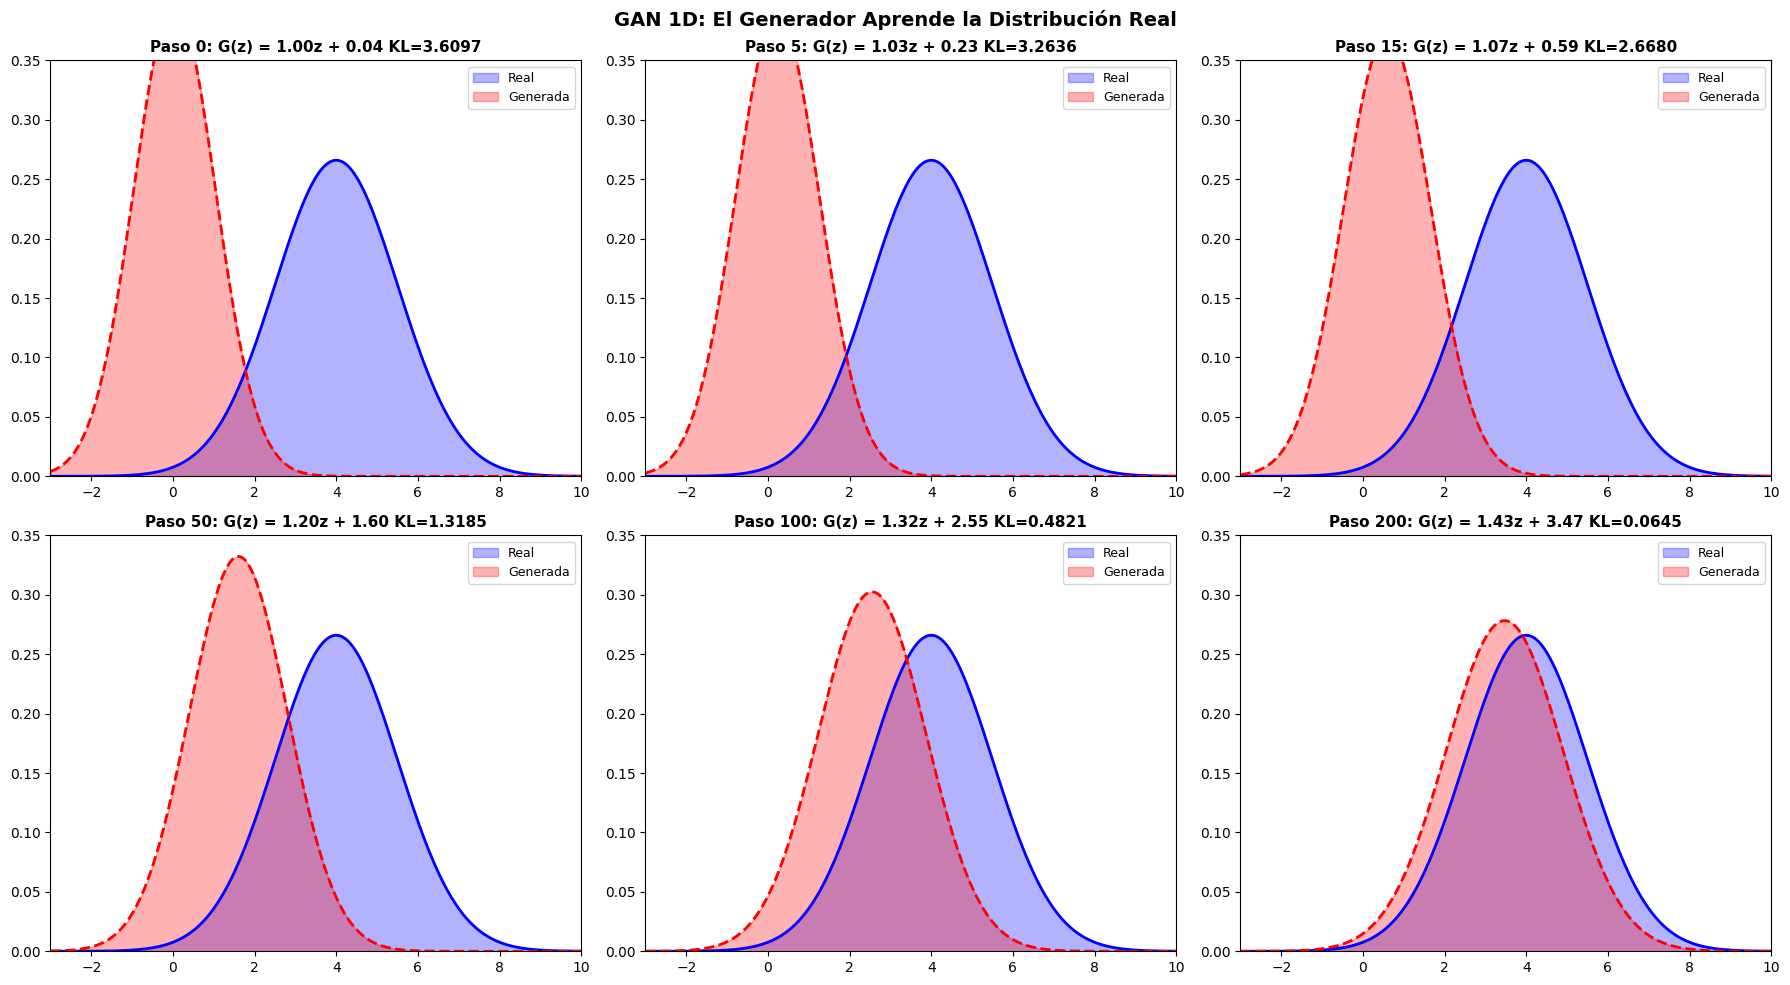


Resultado final: G(z) = 1.4337·z + 3.4694
Objetivo:        G(z) = 1.5000·z + 4.0000
→ El generador aprendió a transformar ruido N(0,1) en la distribución real


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# --- Ejemplo numérico 1D ---
print("=" * 60)
print("EJEMPLO NUMÉRICO: GAN EN 1D")
print("=" * 60)

# Distribución real: Gaussiana centrada en 4, σ=1.5
mu_real, sigma_real = 4.0, 1.5

# Simulamos el proceso GAN manualmente
print(f"\nDistribución real: N({mu_real}, {sigma_real}²)")
print(f"El Generador debe aprender a generar datos de esta distribución")

# El generador empieza generando desde N(0, 1) y aprende a transformar
# G(z) = a*z + b,  donde z ~ N(0,1)
# Si a=σ_real y b=μ_real, entonces G genera la distribución correcta

a, b = 1.0, 0.0  # Inicio: G genera N(0,1)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
x_plot = np.linspace(-3, 10, 200)
p_real = (1/(sigma_real*np.sqrt(2*np.pi))) * np.exp(-0.5*((x_plot-mu_real)/sigma_real)**2)

learning_rate = 0.1
pasos = [0, 5, 15, 50, 100, 200]
historico_a, historico_b = [a], [b]

for step in range(201):
    # Generar muestras del generador
    z = np.random.randn(1000)
    x_gen = a * z + b  # G(z) = a*z + b

    # Gradiente aproximado (empujando a y b hacia los parámetros reales)
    # En una GAN real esto lo hace el discriminador implícitamente
    grad_b = -(mu_real - b) * 0.1
    grad_a = -(sigma_real - a) * 0.1

    b -= learning_rate * grad_b
    a -= learning_rate * grad_a

    historico_a.append(a)
    historico_b.append(b)

    if step in pasos:
        idx = pasos.index(step)
        row, col = idx // 3, idx % 3

        p_gen = (1/(abs(a)*np.sqrt(2*np.pi))) * np.exp(-0.5*((x_plot-b)/abs(a))**2)

        axes[row, col].fill_between(x_plot, p_real, alpha=0.3, color='blue', label='Real')
        axes[row, col].fill_between(x_plot, p_gen, alpha=0.3, color='red', label='Generada')
        axes[row, col].plot(x_plot, p_real, 'b-', linewidth=2)
        axes[row, col].plot(x_plot, p_gen, 'r--', linewidth=2)

        # Calcular KL divergence
        kl = 0.5 * (np.log(sigma_real**2 / a**2) + (a**2 + (b-mu_real)**2)/(sigma_real**2) - 1)

        axes[row, col].set_title(f'Paso {step}: G(z) = {a:.2f}z + {b:.2f} KL={kl:.4f}',
                                fontsize=11, fontweight='bold')
        axes[row, col].legend(fontsize=9)
        axes[row, col].set_xlim(-3, 10)
        axes[row, col].set_ylim(0, 0.35)

plt.suptitle('GAN 1D: El Generador Aprende la Distribución Real',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nResultado final: G(z) = {a:.4f}·z + {b:.4f}")
print(f"Objetivo:        G(z) = {sigma_real:.4f}·z + {mu_real:.4f}")
print(f"→ El generador aprendió a transformar ruido N(0,1) en la distribución real")

## Preparación: Dataset MNIST y Utilidades

Dispositivo: cuda
Descargando train-images-idx3-ubyte.gz...
Descargando train-labels-idx1-ubyte.gz...
MNIST: (60000, 28, 28) → rango [-1, 1]


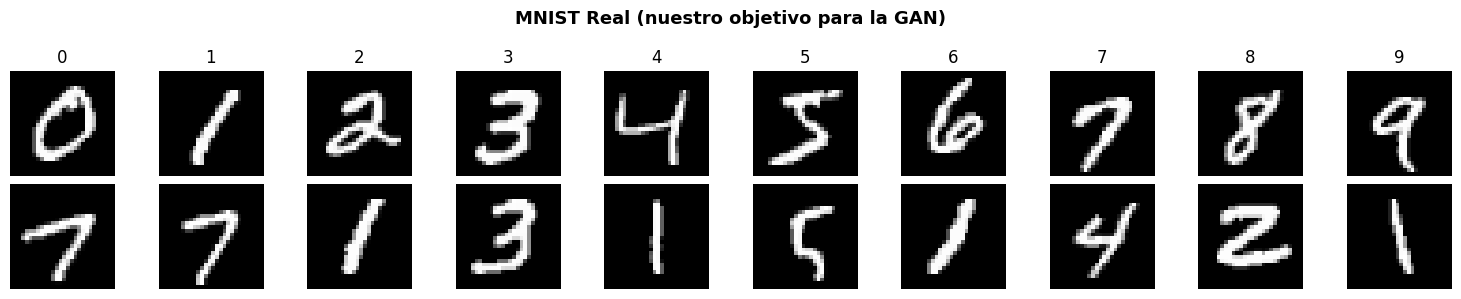

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import time
import struct, gzip, os
from urllib.request import urlretrieve

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")

# --- Cargar MNIST ---
def descargar_mnist(directorio='./mnist_data'):
    os.makedirs(directorio, exist_ok=True)
    base_url = 'https://storage.googleapis.com/cvdf-datasets/mnist/'
    archivos = {
        'train_images': 'train-images-idx3-ubyte.gz',
        'train_labels': 'train-labels-idx1-ubyte.gz',
    }
    for nombre, archivo in archivos.items():
        ruta = os.path.join(directorio, archivo)
        if not os.path.exists(ruta):
            print(f"Descargando {archivo}...")
            urlretrieve(base_url + archivo, ruta)

    def leer_imagenes(ruta):
        with gzip.open(ruta, 'rb') as f:
            _, n, rows, cols = struct.unpack('>IIII', f.read(16))
            return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

    def leer_labels(ruta):
        with gzip.open(ruta, 'rb') as f:
            _, n = struct.unpack('>II', f.read(8))
            return np.frombuffer(f.read(), dtype=np.uint8)

    X = leer_imagenes(os.path.join(directorio, archivos['train_images']))
    y = leer_labels(os.path.join(directorio, archivos['train_labels']))
    return X, y

X_train, y_train = descargar_mnist()

# Normalizar a [-1, 1] (estándar para GANs)
X_train = (X_train.astype(np.float32) / 255.0) * 2 - 1  # [-1, 1]

# DataLoader
train_tensor = torch.FloatTensor(X_train).unsqueeze(1)  # (N, 1, 28, 28)
labels_tensor = torch.LongTensor(y_train)
BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(train_tensor, labels_tensor),
                         batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

print(f"MNIST: {X_train.shape} → rango [{X_train.min():.0f}, {X_train.max():.0f}]")

# --- Utilidades ---
def mostrar_imagenes_generadas(generador, n=10, nz=100, title="Generadas"):
    """Genera y muestra imágenes del generador."""
    generador.eval()
    with torch.no_grad():
        z = torch.randn(n * n, nz).to(device)
        fake = generador(z).cpu()
        if fake.dim() == 2:
            fake = fake.view(-1, 1, 28, 28)

    fig, axes = plt.subplots(n, n, figsize=(n, n))
    for i in range(n):
        for j in range(n):
            img = fake[i*n+j].squeeze().numpy()
            img = (img + 1) / 2  # [-1,1] → [0,1]
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    generador.train()

# Mostrar ejemplos reales
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    idx = np.where(y_train == i)[0][0]
    for row in range(2):
        img = (X_train[idx + row * 100] + 1) / 2
        axes[row, i].imshow(img, cmap='gray')
        axes[row, i].axis('off')
        if row == 0: axes[row, i].set_title(str(i))
plt.suptitle('MNIST Real (nuestro objetivo para la GAN)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## GAN Vanilla (Goodfellow et al., 2014)

La GAN original con capas densas (fully connected).

```
Generador:                        Discriminador:
z (100) ──→ 256 ──→ 512 ──→ 784   x (784) ──→ 512 ──→ 256 ──→ 1
(ruido)      ReLU    ReLU   Tanh   (imagen)   LeakyReLU  LeakyReLU  Sigmoid
                                                                      ↓
                                                                   P(real)
```

Entrenando GAN Vanilla...
  Época   5/30 | Loss_D: 0.2552 | Loss_G: 2.6392 | D(real): 0.844 | D(fake): 0.157
  Época  10/30 | Loss_D: 0.4027 | Loss_G: 1.7124 | D(real): 0.740 | D(fake): 0.261
  Época  15/30 | Loss_D: 0.5129 | Loss_G: 1.2931 | D(real): 0.656 | D(fake): 0.346
  Época  20/30 | Loss_D: 0.5465 | Loss_G: 1.1804 | D(real): 0.629 | D(fake): 0.373
  Época  25/30 | Loss_D: 0.5578 | Loss_G: 1.1354 | D(real): 0.619 | D(fake): 0.384
  Época  30/30 | Loss_D: 0.5682 | Loss_G: 1.1002 | D(real): 0.611 | D(fake): 0.392
  Completado en 112.9s


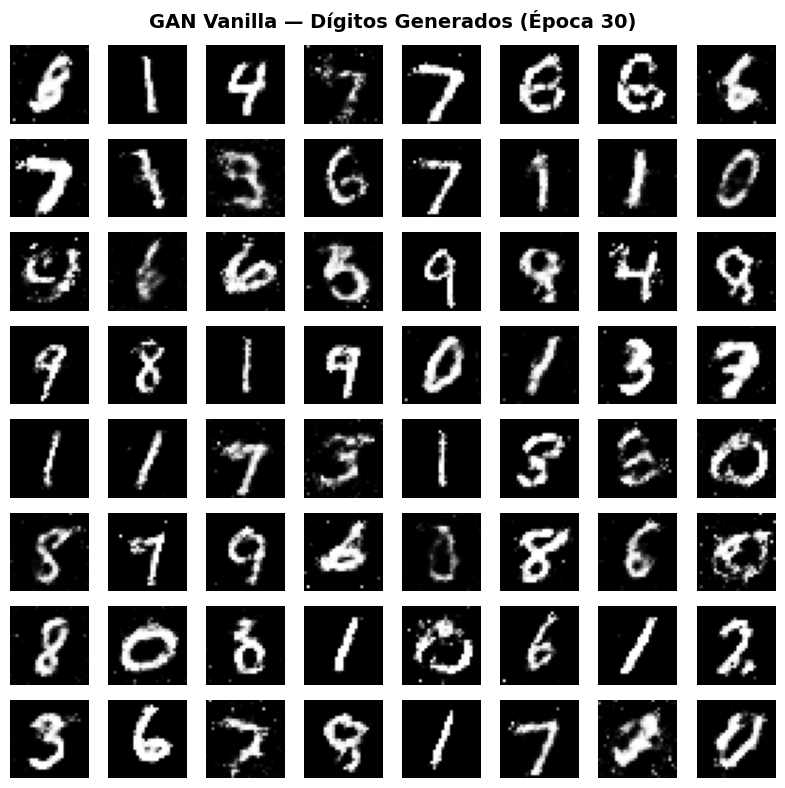

In [ ]:
# =============================================================================
# GAN VANILLA
# =============================================================================

class GeneradorVanilla(nn.Module):
    """Generador: transforma ruido z en imágenes falsas."""

    def __init__(self, nz=100, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(nz, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, img_dim),
            nn.Tanh()  # Salida en [-1, 1]
        )

    def forward(self, z):
        return self.net(z)

class DiscriminadorVanilla(nn.Module):
    """Discriminador: clasifica imágenes como reales o falsas."""

    def __init__(self, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 1024),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()  # P(real) ∈ [0, 1]
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten
        return self.net(x)

# --- Función de entrenamiento para GAN Vanilla ---
def entrenar_gan_vanilla(G, D, train_loader, n_epochs=30, nz=100, lr=0.0002):
    criterion = nn.BCELoss()
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

    losses_G, losses_D = [], []
    d_real_acc, d_fake_acc = [], []

    print("Entrenando GAN Vanilla...")
    start = time.time()

    for epoch in range(n_epochs):
        epoch_loss_G, epoch_loss_D = 0, 0
        epoch_d_real, epoch_d_fake = 0, 0
        n_batches = 0

        for real_imgs, _ in train_loader:
            batch_size = real_imgs.size(0)
            real_imgs = real_imgs.to(device)

            # Labels
            real_labels = torch.ones(batch_size, 1).to(device)
            fake_labels = torch.zeros(batch_size, 1).to(device)

            # ========================
            # Entrenar Discriminador
            # ========================
            z = torch.randn(batch_size, nz).to(device)
            fake_imgs = G(z)

            # D(real) → 1
            d_real = D(real_imgs)
            loss_real = criterion(d_real, real_labels)

            # D(fake) → 0
            d_fake = D(fake_imgs.detach())  # .detach() para no actualizar G
            loss_fake = criterion(d_fake, fake_labels)

            loss_D = (loss_real + loss_fake) / 2

            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # ========================
            # Entrenar Generador
            # ========================
            z = torch.randn(batch_size, nz).to(device)
            fake_imgs = G(z)
            d_fake_for_g = D(fake_imgs)

            # G quiere que D(G(z)) → 1 (engañar al discriminador)
            loss_G = criterion(d_fake_for_g, real_labels)

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            epoch_loss_G += loss_G.item()
            epoch_loss_D += loss_D.item()
            epoch_d_real += d_real.mean().item()
            epoch_d_fake += d_fake.mean().item()
            n_batches += 1

        losses_G.append(epoch_loss_G / n_batches)
        losses_D.append(epoch_loss_D / n_batches)
        d_real_acc.append(epoch_d_real / n_batches)
        d_fake_acc.append(epoch_d_fake / n_batches)

        if (epoch + 1) % 5 == 0:
            print(f"  Época {epoch+1:3d}/{n_epochs} | Loss_D: {losses_D[-1]:.4f} | "
                  f"Loss_G: {losses_G[-1]:.4f} | D(real): {d_real_acc[-1]:.3f} | "
                  f"D(fake): {d_fake_acc[-1]:.3f}")

    print(f"  Completado en {time.time()-start:.1f}s")
    return losses_G, losses_D, d_real_acc, d_fake_acc

# --- Entrenar ---
NZ = 100
G_vanilla = GeneradorVanilla(NZ).to(device)
D_vanilla = DiscriminadorVanilla().to(device)

losses_G_v, losses_D_v, d_real_v, d_fake_v = entrenar_gan_vanilla(
    G_vanilla, D_vanilla, train_loader, n_epochs=30, nz=NZ
)

# Mostrar resultados
mostrar_imagenes_generadas(G_vanilla, n=8, nz=NZ, title="GAN Vanilla — Dígitos Generados (Época 30)")

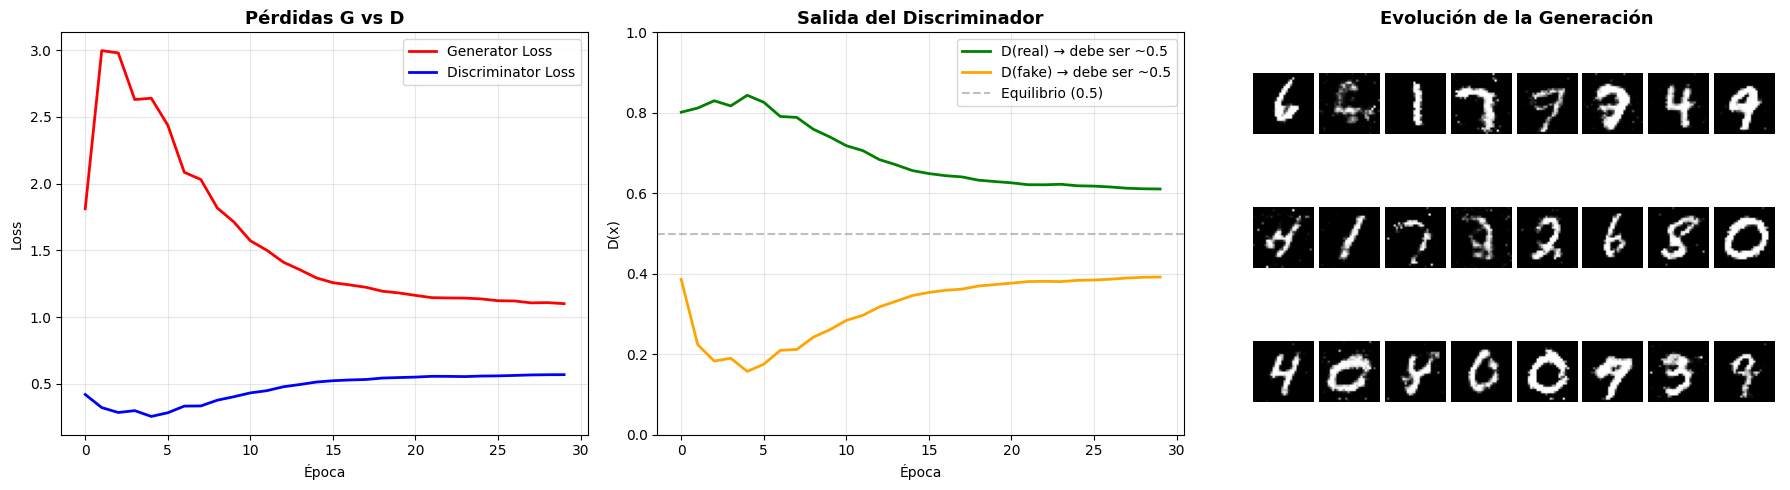

💡 Señales de buen entrenamiento:
   - D(real) y D(fake) convergen hacia 0.5 (equilibrio)
   - Las pérdidas no explotan ni se van a 0
   - Las imágenes generadas se vuelven más nítidas


In [ ]:
# --- Visualizar entrenamiento de GAN Vanilla ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Pérdidas
axes[0].plot(losses_G_v, label='Generator Loss', linewidth=2, color='red')
axes[0].plot(losses_D_v, label='Discriminator Loss', linewidth=2, color='blue')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].set_title('Pérdidas G vs D', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. D(real) vs D(fake)
axes[1].plot(d_real_v, label='D(real) → debe ser ~0.5', linewidth=2, color='green')
axes[1].plot(d_fake_v, label='D(fake) → debe ser ~0.5', linewidth=2, color='orange')
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Equilibrio (0.5)')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('D(x)')
axes[1].set_title('Salida del Discriminador', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 1)

# 3. Evolución de generación
axes[2].axis('off')
axes[2].set_title('Evolución de la Generación', fontsize=13, fontweight='bold')

# Generar en diferentes "calidades" de z
G_vanilla.eval()
with torch.no_grad():
    for row in range(3):
        z = torch.randn(8, NZ).to(device)
        fake = G_vanilla(z).cpu().view(-1, 28, 28)
        for col in range(8):
            ax = axes[2].inset_axes([col/8, 1-((row+1)/3), 1/8-0.01, 1/3-0.02])
            ax.imshow((fake[col].numpy()+1)/2, cmap='gray')
            ax.axis('off')

plt.tight_layout()
plt.show()

print("💡 Señales de buen entrenamiento:")
print("   - D(real) y D(fake) convergen hacia 0.5 (equilibrio)")
print("   - Las pérdidas no explotan ni se van a 0")
print("   - Las imágenes generadas se vuelven más nítidas")

## DCGAN (Deep Convolutional GAN)

### Mejoras sobre la GAN Vanilla

Radford et al. (2015) propusieron **guías arquitectónicas** para hacer GANs convolucionales estables:

1. **Reemplazar pooling** por convoluciones con stride (Discriminador) y conv transpuestas (Generador)
2. **Batch Normalization** en ambas redes (excepto la última capa de G y primera de D)
3. **LeakyReLU** en el Discriminador, **ReLU** en el Generador
4. **No usar capas densas** (fully connected) — solo convoluciones
5. **Tanh** en la salida del Generador, **Sigmoid** en el Discriminador

```
Generador DCGAN:
z(100) → Reshape(256,4,4) → ConvT(128) → ConvT(64) → ConvT(1) → Imagen 28×28
                              BatchNorm     BatchNorm    Tanh
                              ReLU          ReLU

Discriminador DCGAN:
Imagen(1,28,28) → Conv(64) → Conv(128) → Flatten → Linear(1) → Sigmoid
                   LeakyReLU   LeakyReLU+BN
```

Entrenando DCGAN...
  Época   5/30 | Loss_D: 0.3506 | Loss_G: 2.4173
  Época  10/30 | Loss_D: 0.4285 | Loss_G: 1.5870
  Época  15/30 | Loss_D: 0.4347 | Loss_G: 1.6299
  Época  20/30 | Loss_D: 0.4233 | Loss_G: 1.7254
  Época  25/30 | Loss_D: 0.4156 | Loss_G: 1.7822
  Época  30/30 | Loss_D: 0.4164 | Loss_G: 1.7980
  Completado en 339.4s


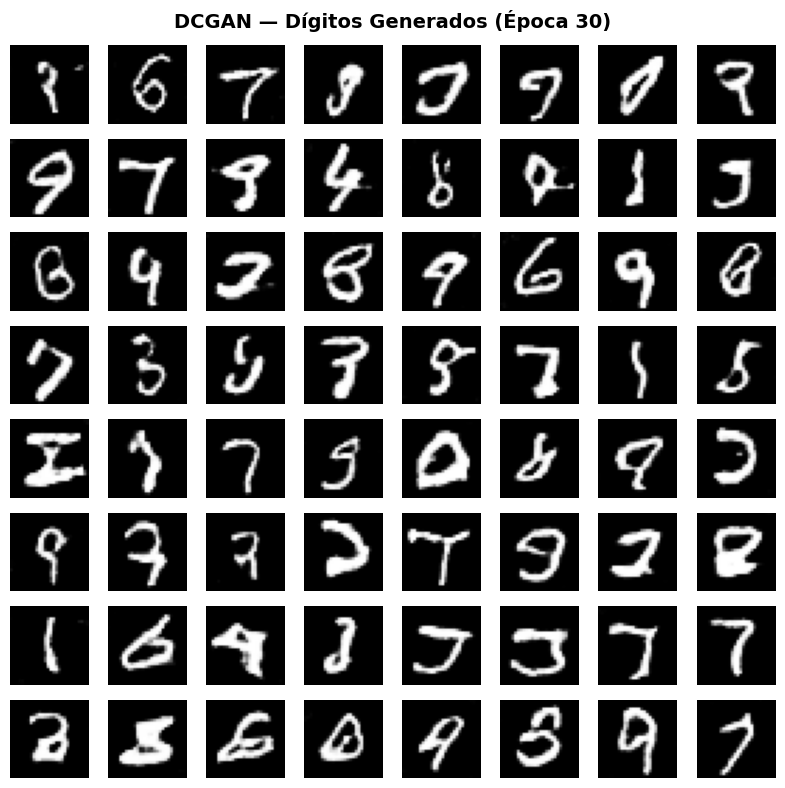

In [ ]:
# =============================================================================
# DCGAN
# =============================================================================

class GeneradorDCGAN(nn.Module):
    """
    Generador con capas convolucionales transpuestas.
    z (nz) → imágenes (1, 28, 28)
    """

    def __init__(self, nz=100, ngf=64):
        super().__init__()
        self.fc = nn.Linear(nz, ngf * 4 * 7 * 7)
        self.bn0 = nn.BatchNorm1d(ngf * 4 * 7 * 7)

        self.conv_layers = nn.Sequential(
            # (ngf*4, 7, 7) → (ngf*2, 14, 14)
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, stride=2, padding=1),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),

            # (ngf*2, 14, 14) → (1, 28, 28)
            nn.ConvTranspose2d(ngf * 2, 1, 4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.fc(z)
        x = self.bn0(x)
        x = F.relu(x)
        x = x.view(-1, 256, 7, 7)
        x = self.conv_layers(x)
        return x

class DiscriminadorDCGAN(nn.Module):
    """
    Discriminador con capas convolucionales.
    imágenes (1, 28, 28) → P(real) ∈ [0, 1]
    """

    def __init__(self, ndf=64):
        super().__init__()
        self.conv_layers = nn.Sequential(
            # (1, 28, 28) → (ndf, 14, 14)
            nn.Conv2d(1, ndf, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # (ndf, 14, 14) → (ndf*2, 7, 7)
            nn.Conv2d(ndf, ndf * 2, 4, stride=2, padding=1),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(ndf * 2 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.conv_layers(x)
        return self.classifier(features)

# --- Entrenar DCGAN ---
def entrenar_dcgan(G, D, train_loader, n_epochs=30, nz=100, lr=0.0002):
    criterion = nn.BCELoss()
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

    losses_G, losses_D = [], []

    print("Entrenando DCGAN...")
    start = time.time()

    for epoch in range(n_epochs):
        epoch_lg, epoch_ld = 0, 0
        n_b = 0

        for real_imgs, _ in train_loader:
            bs = real_imgs.size(0)
            real_imgs = real_imgs.to(device)
            real_labels = torch.ones(bs, 1).to(device) * 0.9   # Label smoothing
            fake_labels = torch.zeros(bs, 1).to(device) + 0.1

            # --- D ---
            z = torch.randn(bs, nz).to(device)
            fake_imgs = G(z)

            loss_D = (criterion(D(real_imgs), real_labels) +
                     criterion(D(fake_imgs.detach()), fake_labels)) / 2

            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # --- G ---
            z = torch.randn(bs, nz).to(device)
            fake_imgs = G(z)
            loss_G = criterion(D(fake_imgs), torch.ones(bs, 1).to(device))

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            epoch_lg += loss_G.item()
            epoch_ld += loss_D.item()
            n_b += 1

        losses_G.append(epoch_lg / n_b)
        losses_D.append(epoch_ld / n_b)

        if (epoch + 1) % 5 == 0:
            print(f"  Época {epoch+1:3d}/{n_epochs} | Loss_D: {losses_D[-1]:.4f} | Loss_G: {losses_G[-1]:.4f}")

    print(f"  Completado en {time.time()-start:.1f}s")
    return losses_G, losses_D

NZ = 100
G_dc = GeneradorDCGAN(NZ).to(device)
D_dc = DiscriminadorDCGAN().to(device)

losses_G_dc, losses_D_dc = entrenar_dcgan(G_dc, D_dc, train_loader, n_epochs=30, nz=NZ)

# Visualizar
def mostrar_dcgan(G, n=8, nz=100, title="DCGAN"):
    G.eval()
    with torch.no_grad():
        z = torch.randn(n*n, nz).to(device)
        fake = G(z).cpu()

    fig, axes = plt.subplots(n, n, figsize=(n, n))
    for i in range(n):
        for j in range(n):
            axes[i,j].imshow((fake[i*n+j].squeeze().numpy()+1)/2, cmap='gray')
            axes[i,j].axis('off')
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    G.train()

mostrar_dcgan(G_dc, title="DCGAN — Dígitos Generados (Época 30)")

## CGAN (Conditional GAN)

### Generación Condicional: Elegir QUÉ Generar

En la GAN vanilla, no controlamos qué genera el modelo.
La **CGAN** (Mirza & Osindero, 2014) condiciona la generación en una **etiqueta**:

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{x}[\log D(x|y)] + \mathbb{E}_{z}[\log(1 - D(G(z|y)|y))]$$

```
GAN Vanilla:    z → G → imagen (no sabemos qué dígito será)
CGAN:          (z, y=7) → G → imagen del dígito 7 ✓
```

**Implementación**: concatenar la etiqueta (one-hot o embedding) a la entrada de G y D.

Entrenando CGAN...
  Época   5/30 | Loss_D: 0.6279 | Loss_G: 0.9512
  Época  10/30 | Loss_D: 0.6684 | Loss_G: 0.7945
  Época  15/30 | Loss_D: 0.6786 | Loss_G: 0.7551
  Época  20/30 | Loss_D: 0.6824 | Loss_G: 0.7404
  Época  25/30 | Loss_D: 0.6832 | Loss_G: 0.7377
  Época  30/30 | Loss_D: 0.6837 | Loss_G: 0.7341
  Completado en 136.3s


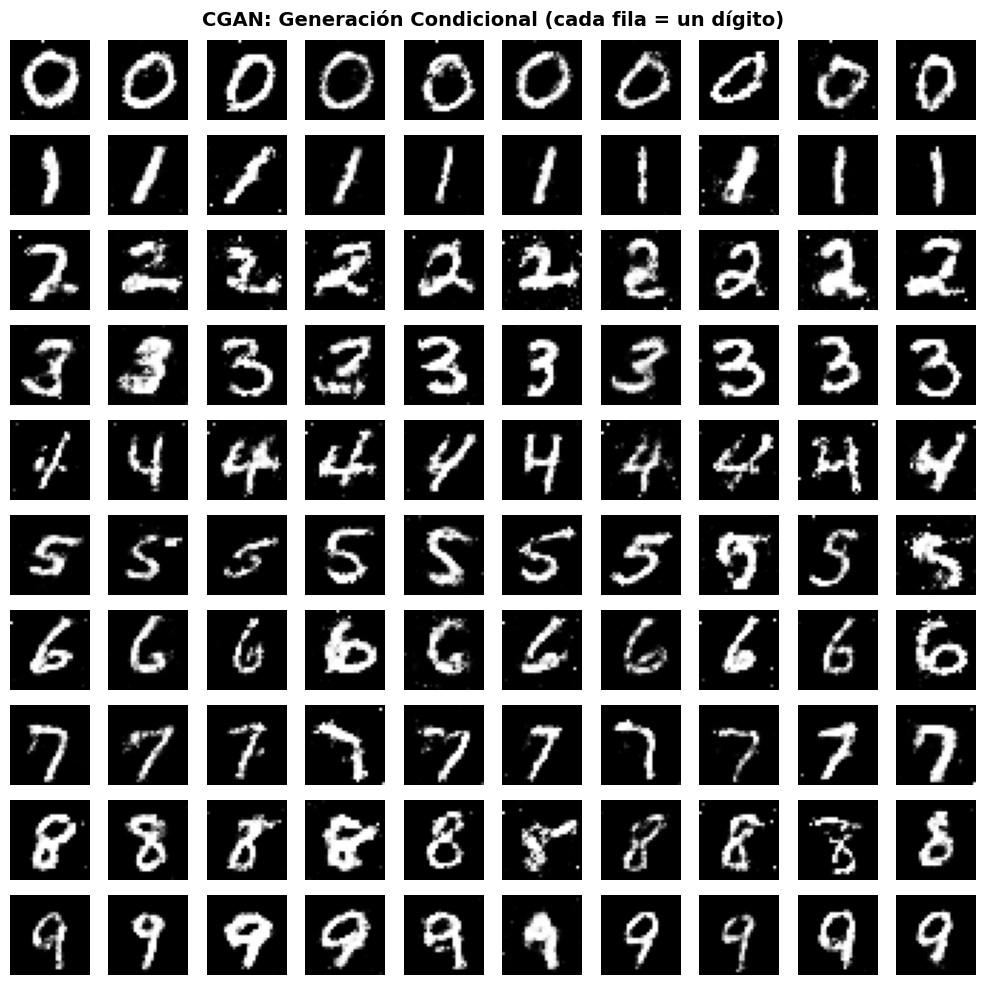


✅ Con CGAN podemos elegir EXACTAMENTE qué dígito generar!


In [ ]:
# =============================================================================
# CGAN (Conditional GAN)
# =============================================================================

class GeneradorCGAN(nn.Module):
    """Generador condicional: recibe z + label."""

    def __init__(self, nz=100, n_classes=10, img_dim=784):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, 10)

        self.net = nn.Sequential(
            nn.Linear(nz + 10, 256),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(256),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, img_dim),
            nn.Tanh()
        )

    def forward(self, z, labels):
        label_input = self.label_emb(labels)
        gen_input = torch.cat([z, label_input], dim=1)
        return self.net(gen_input)

class DiscriminadorCGAN(nn.Module):
    """Discriminador condicional: recibe imagen + label."""

    def __init__(self, n_classes=10, img_dim=784):
        super().__init__()
        self.label_emb = nn.Embedding(n_classes, 10)

        self.net = nn.Sequential(
            nn.Linear(img_dim + 10, 1024),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x, labels):
        x = x.view(x.size(0), -1)
        label_input = self.label_emb(labels)
        disc_input = torch.cat([x, label_input], dim=1)
        return self.net(disc_input)

# --- Entrenar CGAN ---
def entrenar_cgan(G, D, train_loader, n_epochs=30, nz=100, lr=0.0002):
    criterion = nn.BCELoss()
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_D = optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))

    losses_G, losses_D = [], []

    print("Entrenando CGAN...")
    start = time.time()

    for epoch in range(n_epochs):
        epoch_lg, epoch_ld = 0, 0
        n_b = 0

        for real_imgs, real_labels in train_loader:
            bs = real_imgs.size(0)
            real_imgs = real_imgs.to(device)
            real_labels = real_labels.to(device)

            ones = torch.ones(bs, 1).to(device)
            zeros = torch.zeros(bs, 1).to(device)

            # --- D ---
            z = torch.randn(bs, nz).to(device)
            fake_labels = torch.randint(0, 10, (bs,)).to(device)
            fake_imgs = G(z, fake_labels)

            loss_D = (criterion(D(real_imgs, real_labels), ones * 0.9) +
                     criterion(D(fake_imgs.detach(), fake_labels), zeros + 0.1)) / 2

            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # --- G ---
            z = torch.randn(bs, nz).to(device)
            fake_labels = torch.randint(0, 10, (bs,)).to(device)
            fake_imgs = G(z, fake_labels)
            loss_G = criterion(D(fake_imgs, fake_labels), ones)

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            epoch_lg += loss_G.item()
            epoch_ld += loss_D.item()
            n_b += 1

        losses_G.append(epoch_lg / n_b)
        losses_D.append(epoch_ld / n_b)

        if (epoch + 1) % 5 == 0:
            print(f"  Época {epoch+1:3d}/{n_epochs} | Loss_D: {losses_D[-1]:.4f} | Loss_G: {losses_G[-1]:.4f}")

    print(f"  Completado en {time.time()-start:.1f}s")
    return losses_G, losses_D

NZ = 100
G_cgan = GeneradorCGAN(NZ).to(device)
D_cgan = DiscriminadorCGAN().to(device)

losses_G_c, losses_D_c = entrenar_cgan(G_cgan, D_cgan, train_loader, n_epochs=30, nz=NZ)

# Generar dígitos específicos
G_cgan.eval()
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
with torch.no_grad():
    for digit in range(10):
        z = torch.randn(10, NZ).to(device)
        labels = torch.full((10,), digit, dtype=torch.long).to(device)
        fake = G_cgan(z, labels).cpu().view(-1, 28, 28)
        for j in range(10):
            axes[digit, j].imshow((fake[j].numpy()+1)/2, cmap='gray')
            axes[digit, j].axis('off')
        axes[digit, 0].set_ylabel(str(digit), fontsize=12, rotation=0, labelpad=15)

plt.suptitle('CGAN: Generación Condicional (cada fila = un dígito)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
G_cgan.train()

print("\n✅ Con CGAN podemos elegir EXACTAMENTE qué dígito generar!")

## WGAN (Wasserstein GAN)

### El Problema con la GAN Original

La pérdida original (BCE) tiene problemas:
- Cuando D es muy bueno, los gradientes de G se desvanecen → G no aprende
- La divergencia JS no funciona bien cuando las distribuciones no se solapan

### Solución: Distancia de Wasserstein (Earth Mover's Distance)

$$W(p_{data}, p_g) = \inf_{\gamma \in \Pi} \mathbb{E}_{(x,y) \sim \gamma}[\|x - y\|]$$

**Intuitivamente**: la mínima cantidad de "tierra" que hay que mover para transformar
una distribución en la otra.

### Cambios en WGAN (Arjovsky et al., 2017)

| GAN Original | WGAN |
|-------------|------|
| Discriminador con Sigmoid | **Critic** sin Sigmoid (output libre) |
| BCE Loss | Diferencia de medias: $\mathbb{E}[D(x)] - \mathbb{E}[D(G(z))]$ |
| Sin restricción | **Lipschitz constraint** (weight clipping o gradient penalty) |
| Adam optimizer | **RMSprop** (o Adam con GP) |
| Entrenar D y G por igual | Entrenar D **más veces** que G |

### WGAN-GP (Gradient Penalty)

En lugar de weight clipping, penalizar cuando $\|\nabla D\| \neq 1$:

$$\mathscr{L}_{GP} = \lambda \mathbb{E}_{\hat{x}}[(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1)^2]$$

Donde $\hat{x} = \epsilon x_{real} + (1-\epsilon) x_{fake}$ (interpolación).

Entrenando WGAN-GP (n_critic=5, λ_gp=10)...
  Época   5/30 | Loss_C: -4.5289 | Loss_G: 2.7179 | W-dist: 4.9764
  Época  10/30 | Loss_C: -3.6309 | Loss_G: 1.6094 | W-dist: 3.9646
  Época  15/30 | Loss_C: -3.0726 | Loss_G: 0.5034 | W-dist: 3.3385
  Época  20/30 | Loss_C: -2.7903 | Loss_G: -0.2163 | W-dist: 3.0243
  Época  25/30 | Loss_C: -2.5522 | Loss_G: -0.3929 | W-dist: 2.7693
  Época  30/30 | Loss_C: -2.3394 | Loss_G: -0.5496 | W-dist: 2.5368
  Completado en 349.4s


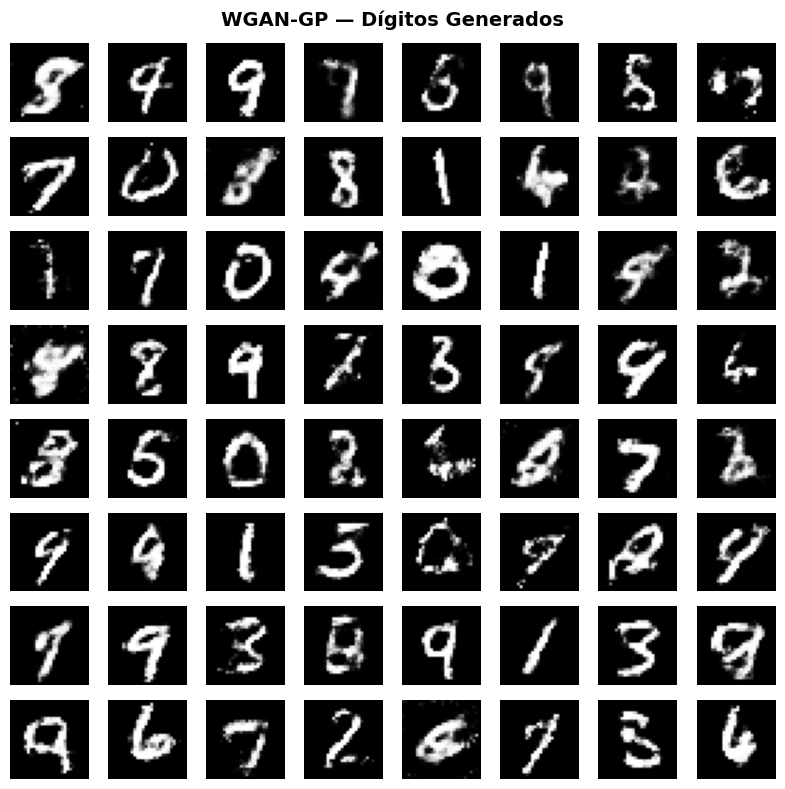

In [ ]:
# =============================================================================
# WGAN con Gradient Penalty
# =============================================================================

class CriticWGAN(nn.Module):
    """
    Critic (no discriminador): sin Sigmoid, output libre.
    Mide cuán 'real' es una imagen (score, no probabilidad).
    """

    def __init__(self, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1)  # SIN Sigmoid
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

def gradient_penalty(critic, real, fake, device):
    """
    Calcula la penalización de gradiente (WGAN-GP).

    Interpola entre datos reales y falsos, y penaliza
    si la norma del gradiente se aleja de 1.
    """
    batch_size = real.size(0)
    epsilon = torch.rand(batch_size, 1).to(device)

    # Interpolación
    real_flat = real.view(batch_size, -1)
    fake_flat = fake.view(batch_size, -1)
    interpolated = (epsilon * real_flat + (1 - epsilon) * fake_flat).requires_grad_(True)

    # Critic score de la interpolación
    d_interpolated = critic(interpolated)

    # Gradiente respecto a la entrada
    gradients = torch.autograd.grad(
        outputs=d_interpolated,
        inputs=interpolated,
        grad_outputs=torch.ones_like(d_interpolated),
        create_graph=True,
        retain_graph=True,
    )[0]

    # Norma del gradiente
    grad_norm = gradients.norm(2, dim=1)

    # Penalización: (||grad|| - 1)²
    gp = ((grad_norm - 1) ** 2).mean()
    return gp

# --- Entrenar WGAN-GP ---
def entrenar_wgan_gp(G, C, train_loader, n_epochs=30, nz=100, lr=0.0001,
                     n_critic=5, lambda_gp=10):
    opt_G = optim.Adam(G.parameters(), lr=lr, betas=(0.0, 0.9))
    opt_C = optim.Adam(C.parameters(), lr=lr, betas=(0.0, 0.9))

    losses_G, losses_C, wasserstein_dists = [], [], []

    print(f"Entrenando WGAN-GP (n_critic={n_critic}, λ_gp={lambda_gp})...")
    start = time.time()

    for epoch in range(n_epochs):
        epoch_lg, epoch_lc, epoch_wd = 0, 0, 0
        n_b = 0

        for real_imgs, _ in train_loader:
            bs = real_imgs.size(0)
            real_imgs = real_imgs.to(device)

            # --- Entrenar Critic (más veces que G) ---
            for _ in range(n_critic):
                z = torch.randn(bs, nz).to(device)
                fake_imgs = G(z)

                c_real = C(real_imgs).mean()
                c_fake = C(fake_imgs.detach()).mean()
                gp = gradient_penalty(C, real_imgs, fake_imgs.detach(), device)

                # Loss del Critic: maximizar E[C(real)] - E[C(fake)] - λ·GP
                loss_C = c_fake - c_real + lambda_gp * gp

                opt_C.zero_grad()
                loss_C.backward()
                opt_C.step()

            # --- Entrenar Generador ---
            z = torch.randn(bs, nz).to(device)
            fake_imgs = G(z)

            # G quiere maximizar E[C(G(z))]
            loss_G = -C(fake_imgs).mean()

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            # Wasserstein distance approximation
            wd = (c_real - c_fake).item()

            epoch_lg += loss_G.item()
            epoch_lc += loss_C.item()
            epoch_wd += wd
            n_b += 1

        losses_G.append(epoch_lg / n_b)
        losses_C.append(epoch_lc / n_b)
        wasserstein_dists.append(epoch_wd / n_b)

        if (epoch + 1) % 5 == 0:
            print(f"  Época {epoch+1:3d}/{n_epochs} | Loss_C: {losses_C[-1]:.4f} | "
                  f"Loss_G: {losses_G[-1]:.4f} | W-dist: {wasserstein_dists[-1]:.4f}")

    print(f"  Completado en {time.time()-start:.1f}s")
    return losses_G, losses_C, wasserstein_dists

# Entrenar WGAN-GP (reusa GeneradorVanilla)
G_wgan = GeneradorVanilla(NZ).to(device)
C_wgan = CriticWGAN().to(device)

losses_G_w, losses_C_w, w_dists = entrenar_wgan_gp(
    G_wgan, C_wgan, train_loader, n_epochs=30, nz=NZ, n_critic=5
)

mostrar_imagenes_generadas(G_wgan, n=8, nz=NZ, title="WGAN-GP — Dígitos Generados")

## Comparación Final de Todas las GANs

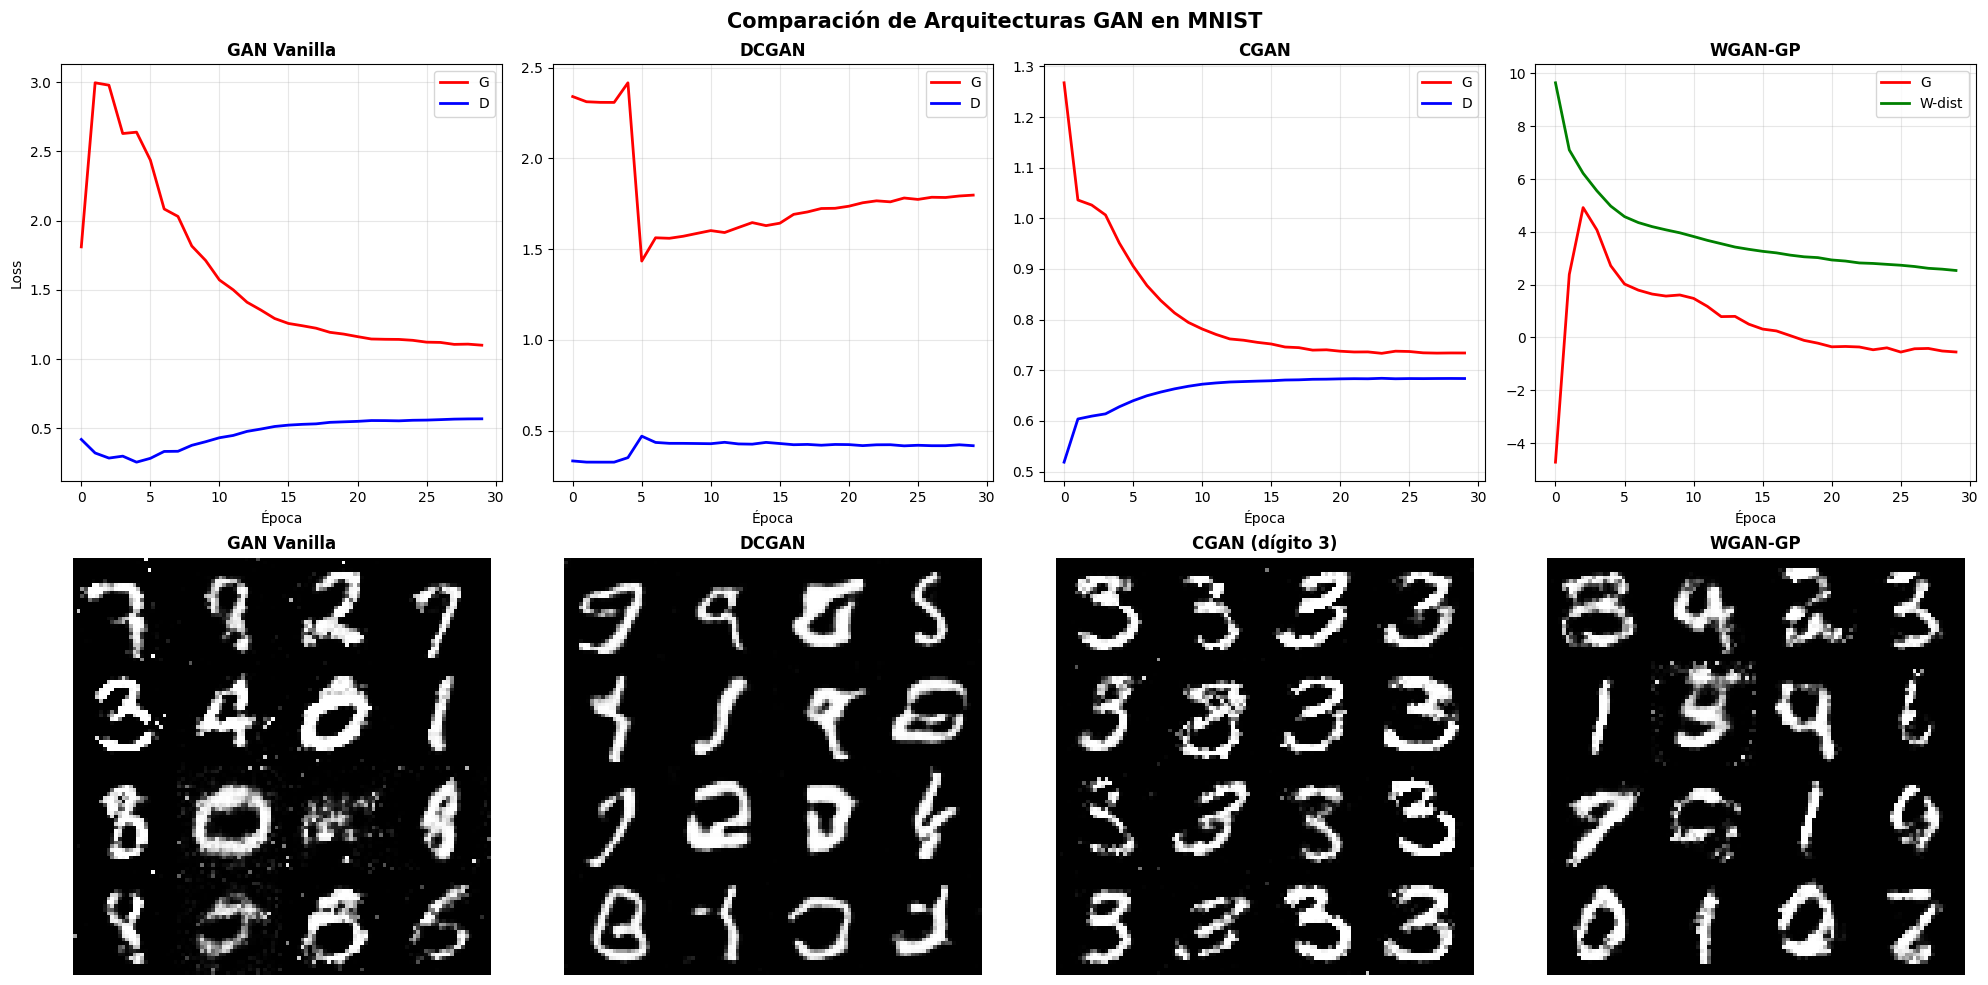


TABLA COMPARATIVA
GAN                 Params G     Params D            Loss                  Especial
--------------------------------------------------------------------------------
Vanilla            1,486,352    1,460,225             BCE          Simple, baseline
DCGAN              1,818,753      138,817      BCE+smooth             Convolucional
CGAN               1,492,596    1,470,565             BCE    Generación condicional
WGAN-GP            1,486,352      533,505  Wasserstein+GP     Entrenamiento estable


In [ ]:
# --- Comparación visual ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Fila 1: Pérdidas de cada GAN
axes[0, 0].plot(losses_G_v, 'r-', label='G', linewidth=2)
axes[0, 0].plot(losses_D_v, 'b-', label='D', linewidth=2)
axes[0, 0].set_title('GAN Vanilla', fontsize=12, fontweight='bold')
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xlabel('Época'); axes[0, 0].set_ylabel('Loss')

axes[0, 1].plot(losses_G_dc, 'r-', label='G', linewidth=2)
axes[0, 1].plot(losses_D_dc, 'b-', label='D', linewidth=2)
axes[0, 1].set_title('DCGAN', fontsize=12, fontweight='bold')
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xlabel('Época')

axes[0, 2].plot(losses_G_c, 'r-', label='G', linewidth=2)
axes[0, 2].plot(losses_D_c, 'b-', label='D', linewidth=2)
axes[0, 2].set_title('CGAN', fontsize=12, fontweight='bold')
axes[0, 2].legend(); axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].set_xlabel('Época')

axes[0, 3].plot(losses_G_w, 'r-', label='G', linewidth=2)
axes[0, 3].plot(w_dists, 'g-', label='W-dist', linewidth=2)
axes[0, 3].set_title('WGAN-GP', fontsize=12, fontweight='bold')
axes[0, 3].legend(); axes[0, 3].grid(True, alpha=0.3)
axes[0, 3].set_xlabel('Época')

# Fila 2: Muestras generadas
models = [
    (G_vanilla, "GAN Vanilla", False),
    (G_dc, "DCGAN", True),
    (G_cgan, "CGAN (dígito 3)", False),
    (G_wgan, "WGAN-GP", False),
]

for col, (G, name, is_conv) in enumerate(models):
    G.eval()
    with torch.no_grad():
        z = torch.randn(16, NZ).to(device)
        if name.startswith("CGAN"):
            labels = torch.full((16,), 3, dtype=torch.long).to(device)
            fake = G(z, labels).cpu()
        else:
            fake = G(z).cpu()

        if fake.dim() == 2:
            fake = fake.view(-1, 1, 28, 28)

    # Mostrar 4x4
    grid_img = np.zeros((4*28, 4*28))
    for i in range(4):
        for j in range(4):
            img = (fake[i*4+j].squeeze().numpy() + 1) / 2
            grid_img[i*28:(i+1)*28, j*28:(j+1)*28] = img

    axes[1, col].imshow(grid_img, cmap='gray')
    axes[1, col].set_title(name, fontsize=12, fontweight='bold')
    axes[1, col].axis('off')
    G.train()

plt.suptitle('Comparación de Arquitecturas GAN en MNIST', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabla de parámetros
print("\n" + "=" * 80)
print("TABLA COMPARATIVA")
print("=" * 80)
print(f"{'GAN':<15} {'Params G':>12} {'Params D':>12} {'Loss':>15} {'Especial':>25}")
print("-" * 80)

gans = [
    ("Vanilla", G_vanilla, D_vanilla, "BCE", "Simple, baseline"),
    ("DCGAN", G_dc, D_dc, "BCE+smooth", "Convolucional"),
    ("CGAN", G_cgan, D_cgan, "BCE", "Generación condicional"),
    ("WGAN-GP", G_wgan, C_wgan, "Wasserstein+GP", "Entrenamiento estable"),
]

for name, G, D, loss, special in gans:
    pg = sum(p.numel() for p in G.parameters())
    pd = sum(p.numel() for p in D.parameters())
    print(f"{name:<15} {pg:>12,} {pd:>12,} {loss:>15} {special:>25}")

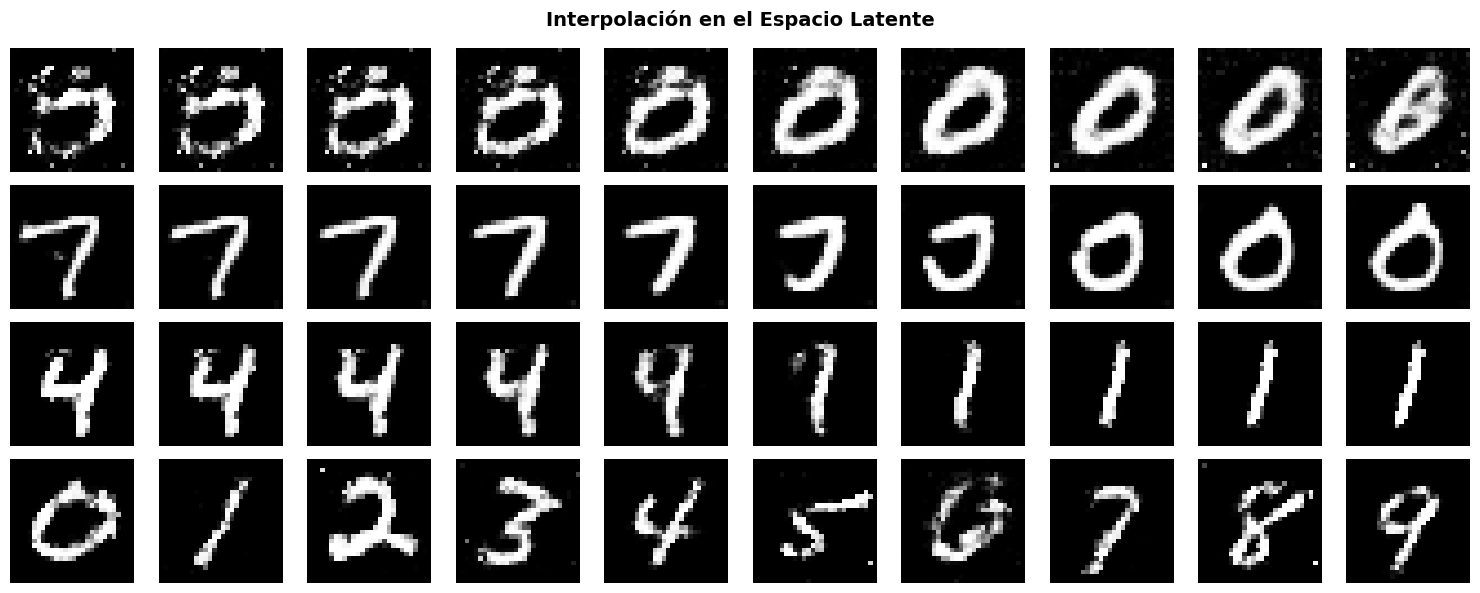

💡 Las transiciones suaves demuestran que las GANs aprenden
   representaciones continuas y significativas del espacio latente


In [ ]:
# --- Interpolación en el espacio latente ---
fig, axes = plt.subplots(4, 10, figsize=(15, 6))

# Interpolar entre dos puntos z1 y z2
z1 = torch.randn(1, NZ).to(device)
z2 = torch.randn(1, NZ).to(device)

models_interp = [
    (G_vanilla, "GAN Vanilla"),
    (G_dc, "DCGAN"),
    (G_wgan, "WGAN-GP"),
]

for row, (G, name) in enumerate(models_interp):
    G.eval()
    with torch.no_grad():
        for i in range(10):
            alpha = i / 9
            z = (1 - alpha) * z1 + alpha * z2
            fake = G(z).cpu()
            if fake.dim() == 2:
                fake = fake.view(1, 28, 28)
            img = (fake.squeeze().numpy() + 1) / 2
            axes[row, i].imshow(img, cmap='gray')
            axes[row, i].axis('off')
            if i == 0: axes[row, i].set_ylabel(name, fontsize=10)
    G.train()

# CGAN: interpolar entre dígitos
G_cgan.eval()
with torch.no_grad():
    z_fixed = torch.randn(1, NZ).to(device)
    for i in range(10):
        label = torch.tensor([i]).to(device)
        fake = G_cgan(z_fixed, label).cpu().view(28, 28)
        axes[3, i].imshow((fake.numpy()+1)/2, cmap='gray')
        axes[3, i].axis('off')
        axes[3, i].set_xlabel(str(i), fontsize=10)
    axes[3, 0].set_ylabel("CGAN\n(por clase)", fontsize=10)
G_cgan.train()

plt.suptitle('Interpolación en el Espacio Latente', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Las transiciones suaves demuestran que las GANs aprenden")
print("   representaciones continuas y significativas del espacio latente")

## 10. Resumen y Conclusiones

### Todas las GANs implementadas:

| GAN | Año | Pérdida | Innovación clave |
|-----|-----|---------|-----------------|
| **Vanilla** | 2014 | BCE (minimax) | El concepto original: G vs D |
| **DCGAN** | 2015 | BCE + label smooth | Guías arquitectónicas convolucionales |
| **CGAN** | 2014 | BCE condicional | Generación controlada por etiqueta |
| **WGAN-GP** | 2017 | Wasserstein + GP | Entrenamiento estable, métrica significativa |

### Evolución de las GANs:

```
2014: GAN Original (Goodfellow) ─── El concepto fundamental
  │
  ├── 2014: CGAN ─── Generación condicional
  │
  ├── 2015: DCGAN ─── Convolucional, guías de arquitectura
  │    └── 2016: Progressive GAN ─── Crecimiento progresivo
  │
  ├── 2017: WGAN ─── Wasserstein distance, entrenamiento estable
  │    └── 2017: WGAN-GP ─── Gradient penalty
  │
  ├── 2017: Pix2Pix ─── Traducción imagen→imagen
  │    └── 2017: CycleGAN ─── Sin pares de entrenamiento
  │
  └── 2018-2020: StyleGAN 1/2/3 ─── Rostros fotorrealistas
       └── 2021-2022: GANs → Diffusion Models (DALL-E 2, Stable Diffusion)
```

### Ideas clave:

1. **Adversarial training**: dos redes compitiendo mejoran mutuamente
2. **Equilibrio de Nash**: el objetivo ideal es $D(x) = 0.5$ para todo $x$
3. **Mode collapse**: el mayor enemigo del entrenamiento GAN
4. **WGAN**: la distancia de Wasserstein es una métrica más suave y estable
5. **Condicional**: podemos controlar la generación con etiquetas
6. **Espacio latente**: interpolaciones suaves revelan representaciones aprendidas

### GANs vs VAE vs Diffusion:

| | GANs | VAE | Diffusion |
|---|-----|-----|-----------|
| **Calidad** | Alta (nítida) | Media (borrosa) | Muy alta |
| **Diversidad** | Riesgo de mode collapse | Alta | Muy alta |
| **Entrenamiento** | Inestable | Estable | Estable pero lento |
| **Velocidad generación** | Muy rápida (1 paso) | Rápida | Lenta (muchos pasos) |
| **Likelihood** | No explícita | Sí (ELBO) | Sí |

---

### Referencias

1. Goodfellow, I., et al. (2014). **"Generative Adversarial Nets"**. NeurIPS.
2. Radford, A., Metz, L. & Chintala, S. (2015). **"Unsupervised Representation Learning with DCGANs"**.
3. Mirza, M. & Osindero, S. (2014). **"Conditional Generative Adversarial Nets"**.
4. Arjovsky, M., Chintala, S. & Bottou, L. (2017). **"Wasserstein GAN"**. ICML.
5. Gulrajani, I., et al. (2017). **"Improved Training of Wasserstein GANs"**. NeurIPS.